In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv("/content/train (1).csv")

In [9]:
FEATURES = ["square_footage", "bedrooms", "bathrooms"]
TARGET = "price"
COLUMN_ALIASES = {
    "square_footage": ["square_footage", "sqft", "sqft_living", "square_feet", "area", "living_area", "grlivarea", "1stflrsf"],
    "bedrooms": ["bedrooms", "bedroom", "num_bedrooms", "beds", "bedroomabvgr"],
    "bathrooms": ["bathrooms", "bathroom", "num_bathrooms", "baths", "fullbath"],
    "price": ["price", "house_price", "saleprice", "sale_price", "selling_price"],
}

In [14]:

# Ensure column names are matched robustly by lowercasing
lookup = {c.strip().lower(): c for c in df.columns}
rename = {}
for std, aliases in COLUMN_ALIASES.items():
    # Search for any alias match in our lowercase lookup table
    match = next((lookup[a.strip().lower()] for a in aliases if a.strip().lower() in lookup), None)
    if match is None:
        raise KeyError(f"No column found for '{std}' using aliases {aliases}. Available columns: {list(df.columns)}")
    rename[match] = std
data = df[list(rename)].rename(columns=rename).apply(pd.to_numeric, errors="coerce").dropna()
print(f"Successfully matched and loaded {len(data)} rows:")
print(data.head())

Successfully matched and loaded 1460 rows:
   square_footage  bedrooms  bathrooms   price
0            1710         3          2  208500
1            1262         3          2  181500
2            1786         3          2  223500
3            1717         3          1  140000
4            2198         4          2  250000


In [11]:
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

In [12]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:,.2f}\nRMSE: {rmse:,.2f}\nR2: {r2:.4f}")
for f, c in zip(FEATURES, model.coef_):
    print(f"  {f}: {c:,.2f}")
print(f"  intercept: {model.intercept_:,.2f}")

MAE: 35,788.06
RMSE: 52,975.72
R2: 0.6341
  square_footage: 104.03
  bedrooms: -26,655.17
  bathrooms: 30,014.32
  intercept: 52,261.75


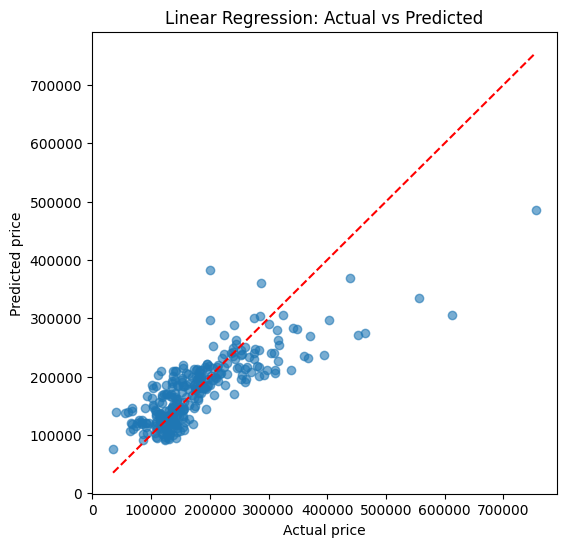

['outputs/linear_regression_model.joblib']

In [15]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()
Path("outputs").mkdir(exist_ok=True)
joblib.dump(model, "outputs/linear_regression_model.joblib")